In [1]:
# Dataset Loading & Basic Inspection

import pandas as pd

df = pd.read_csv(r"C:\Users\krishna\Downloads\archive.zip")
print(df.head())


   Runs  BF  4s  6s     SR  Pos Dismissal  Inns   Opposition         Ground  \
0    12  22   1   0  54.54  2.0       lbw     1  v Sri Lanka       Dambulla   
1    37  67   6   0  55.22  2.0    caught     2  v Sri Lanka       Dambulla   
2    25  38   4   0  65.78  1.0   run out     1  v Sri Lanka  Colombo (RPS)   
3    54  66   7   0  81.81  1.0    bowled     1  v Sri Lanka  Colombo (RPS)   
4    31  46   3   1  67.39  1.0       lbw     2  v Sri Lanka  Colombo (RPS)   

  Start Date  
0  18-Aug-08  
1  20-Aug-08  
2  24-Aug-08  
3  27-Aug-08  
4  29-Aug-08  


In [2]:
# Import Libraries (NumPy, Pandas, Matplotlib, Seaborn)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Make plots look nicer
sns.set(style="whitegrid")


In [3]:
# Data Cleaning (missing values, duplicates, data types)

# Check for missing values


# -------------------------------
# 1. Check for Missing Values
# -------------------------------
print("Missing values per column:")
print(df.isnull().sum())

# Option A: Drop rows with missing values
df = df.dropna()

# Option B: Fill missing values (example: fill numeric with mean, categorical with mode)
# df['Runs'] = df['Runs'].fillna(df['Runs'].mean())
# df['Opponent'] = df['Opponent'].fillna(df['Opponent'].mode()[0])

# -------------------------------
# 2. Remove Duplicates
# -------------------------------
print("Shape before removing duplicates:", df.shape)
df = df.drop_duplicates()
print("Shape after removing duplicates:", df.shape)

# -------------------------------
# 3. Check and Fix Data Types
# -------------------------------
print("Data types before conversion:")
print(df.dtypes)

# Example conversions (adjust based on your dataset)
# Convert 'Date' column to datetime
if 'Date' in df.columns:
    df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

# Convert categorical columns to category type
categorical_cols = ['Opponent', 'Venue', 'Result']
for col in categorical_cols:
    if col in df.columns:
        df[col] = df[col].astype('category')

print("Data types after conversion:")
print(df.dtypes)

# -------------------------------
# 4. Final Cleaned Dataset Summary
# -------------------------------
print("Final dataset shape:", df.shape)
print(df.head())



Missing values per column:
Runs          0
BF            0
4s            0
6s            0
SR            0
Pos           0
Dismissal     0
Inns          0
Opposition    0
Ground        0
Start Date    0
dtype: int64
Shape before removing duplicates: (132, 11)
Shape after removing duplicates: (132, 11)
Data types before conversion:
Runs            int64
BF              int64
4s              int64
6s              int64
SR            float64
Pos           float64
Dismissal      object
Inns            int64
Opposition     object
Ground         object
Start Date     object
dtype: object
Data types after conversion:
Runs            int64
BF              int64
4s              int64
6s              int64
SR            float64
Pos           float64
Dismissal      object
Inns            int64
Opposition     object
Ground         object
Start Date     object
dtype: object
Final dataset shape: (132, 11)
   Runs  BF  4s  6s     SR  Pos Dismissal  Inns   Opposition         Ground  \
0    12  22   1 

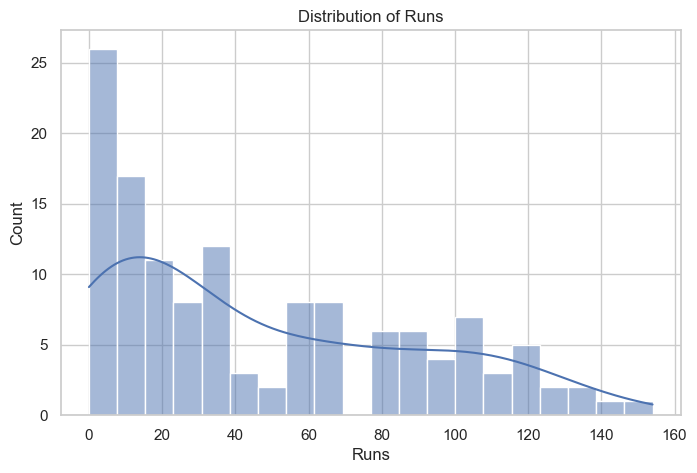

In [4]:
# Univariate Analysis - Bivariate & Multivariate Analysis 

# Example: distribution of runs
plt.figure(figsize=(8,5))
sns.histplot(df['Runs'], bins=20, kde=True)
plt.title("Distribution of Runs")
plt.show()


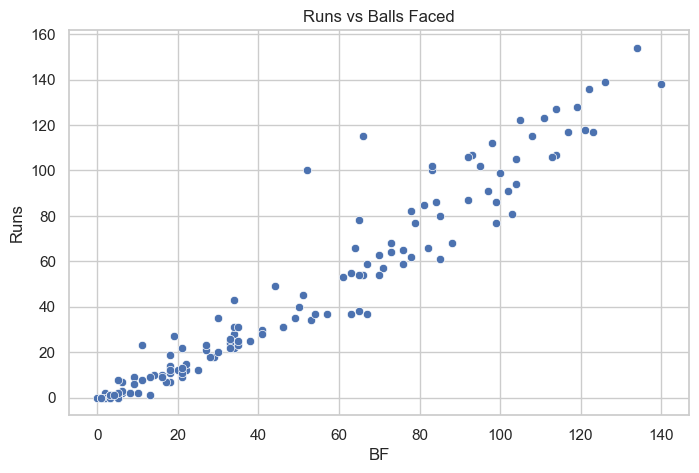

In [5]:
# Univariate Analysis - Bivariate & Multivariate Analysis 

# Example: Runs vs Balls Faced
plt.figure(figsize=(8,5))
sns.scatterplot(x="BF", y="Runs", data=df)
plt.title("Runs vs Balls Faced")
plt.show()


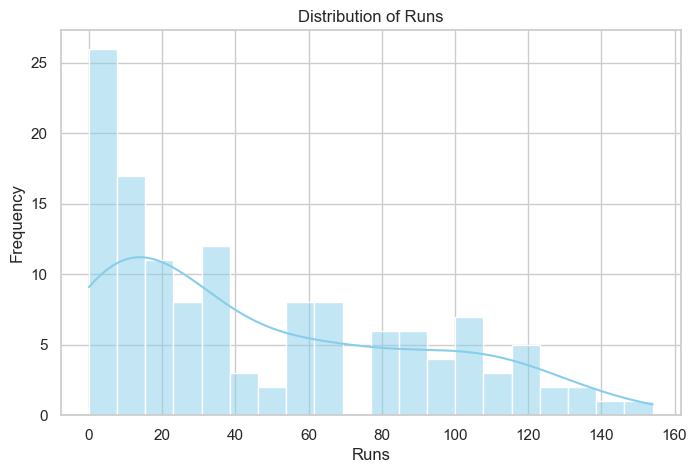

In [6]:
# Visualizations

import matplotlib.pyplot as plt
import seaborn as sns

# 1. Histogram of Runs
plt.figure(figsize=(8,5))
sns.histplot(df['Runs'], bins=20, kde=True, color="skyblue")
plt.title("Distribution of Runs")
plt.xlabel("Runs")
plt.ylabel("Frequency")
plt.show()



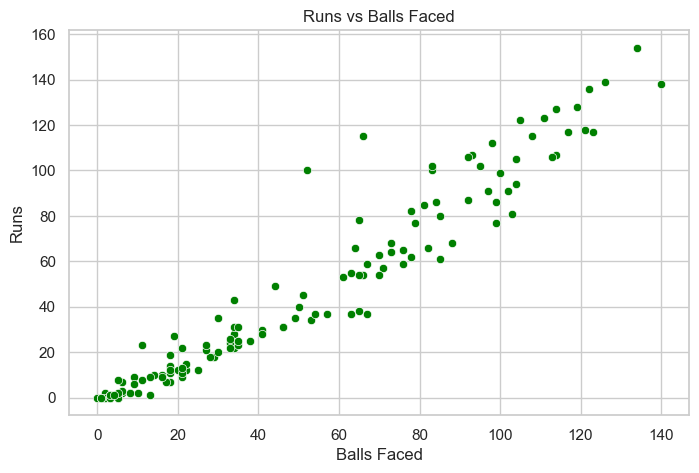

In [7]:
# Visualizations

# 2. Scatterplot: Runs vs Balls Faced
plt.figure(figsize=(8,5))
sns.scatterplot(x="BF", y="Runs", data=df, color="green")
plt.title("Runs vs Balls Faced")
plt.xlabel("Balls Faced")
plt.ylabel("Runs")
plt.show()




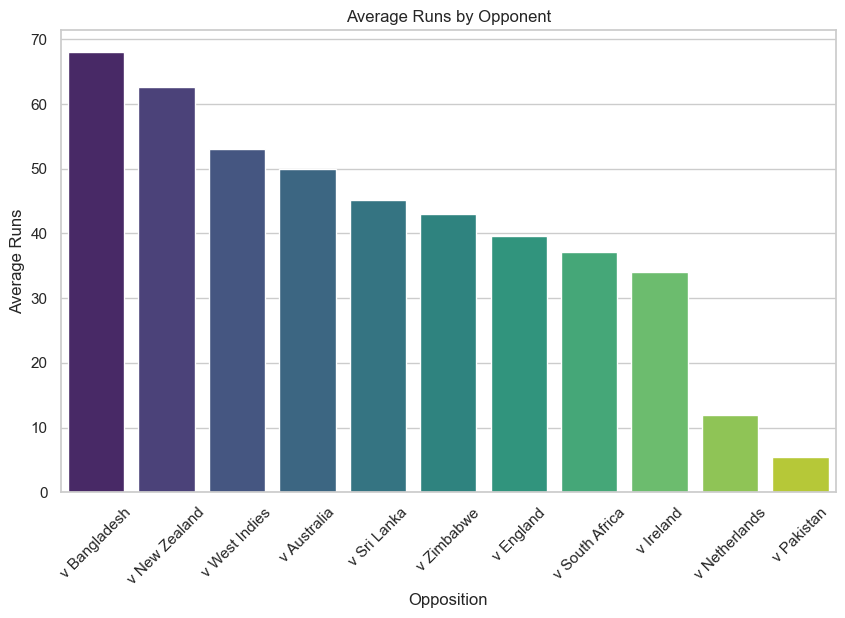

<Figure size 1000x600 with 0 Axes>

<Figure size 1000x600 with 0 Axes>

In [8]:
# Visualizations

# 3. Bar Chart: Average Runs by Opponent
plt.figure(figsize=(10,6))
avg_runs = df.groupby("Opposition")["Runs"].mean().sort_values(ascending=False)
sns.barplot(x=avg_runs.index, y=avg_runs.values, hue=avg_runs.index, palette="viridis", legend=False)
plt.title("Average Runs by Opponent")
plt.xticks(rotation=45)
plt.ylabel("Average Runs")
plt.show()

plt.figure(figsize=(10,6))


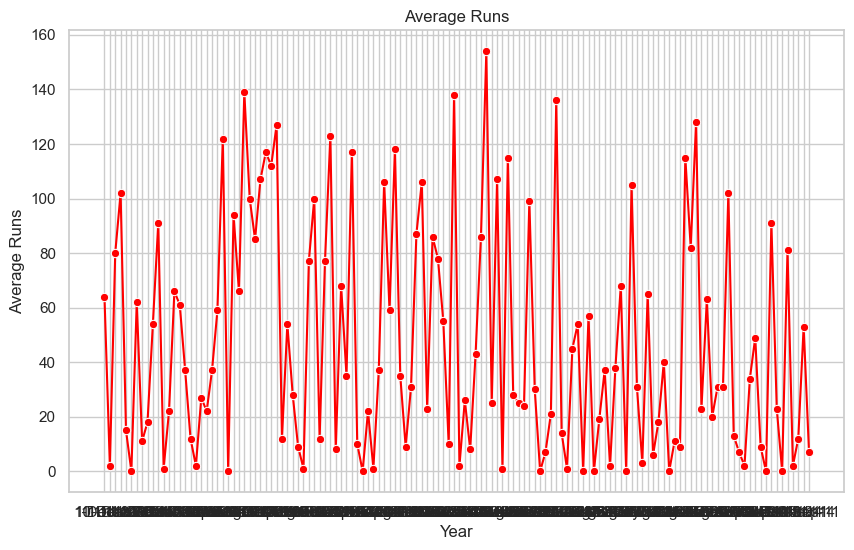

In [9]:
# Visualizations

# 4. Line Plot: Runs Over Time
plt.figure(figsize=(10,6))
yearly_runs = df.groupby("Start Date")["Runs"].mean()
sns.lineplot(x=yearly_runs.index, y=yearly_runs.values, marker="o", color="red")
plt.title("Average Runs")
plt.xlabel("Year")
plt.ylabel("Average Runs")
plt.show()



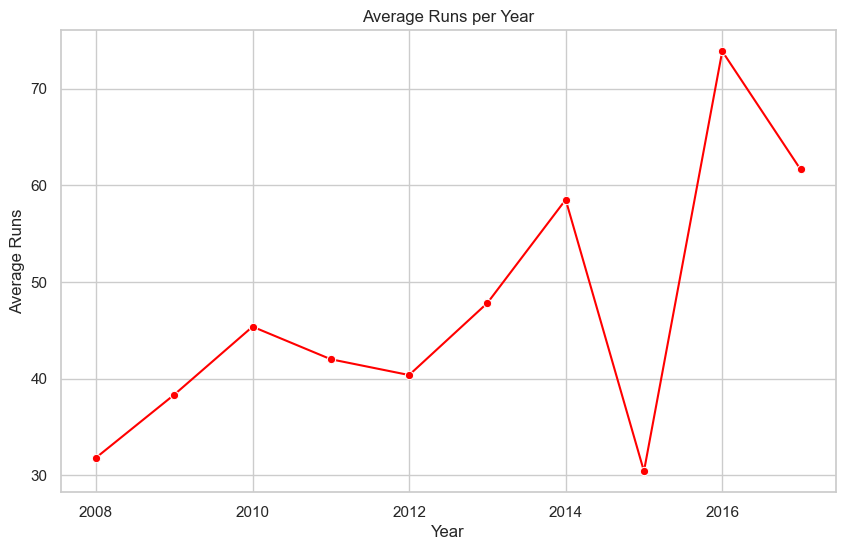

In [11]:
# Visualizations

# 4. Line Plot: Runs Over Time (Yearly)
plt.figure(figsize=(10,6))

# Ensure Start Date is in datetime format
df["Start Date"] = pd.to_datetime(df["Start Date"], format="%d/%m/%Y")

# Extract Year
df["Year"] = df["Start Date"].dt.year

# Group by Year
yearly_runs = df.groupby("Year")["Runs"].mean()

# Plot
sns.lineplot(x=yearly_runs.index, y=yearly_runs.values, marker="o", color="red")
plt.title("Average Runs per Year")
plt.xlabel("Year")
plt.ylabel("Average Runs")
plt.show()


